In [1]:
# CELDA 1 — Instalar dependencias (ejecutar si no lo hiciste)
!pip install -q tensorflow opencv-python-headless scikit-learn matplotlib seaborn

In [1]:
# @title CELDA 3: Verificación de Estructura y Conteo de Imágenes Final
import os

# --- 1. CONFIGURACIÓN ---
# Definimos la carpeta aquí mismo para asegurar que funcione
DATA_DIR = 'dataset_maiz'

# Lista de cosas que NO son clases (basura del sistema)
NON_CLASS_ARTIFACTS = ['__MACOSX', '.ipynb_checkpoints', '.DS_Store']

# --- 2. FUNCIONES ---
def count_images(folder):
    """Cuenta archivos de imagen (jpg, png, etc.) en la carpeta dada."""
    cnt = 0
    valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')
    
    if os.path.isdir(folder):
        for f in os.listdir(folder):
            if f.lower().endswith(valid_exts):
                cnt += 1
    return cnt

# --- 3. EJECUCIÓN PRINCIPAL ---
print(f"🔍 Verificando carpeta: '{DATA_DIR}'...\n")

if not os.path.exists(DATA_DIR):
    print(f"❌ ERROR: No se encontró la carpeta '{DATA_DIR}'.")
    print("   👉 Asegúrate de haber ejecutado la descompresión (Celda 2) correctamente.")
else:
    try:
        # Listar todo el contenido de la carpeta principal
        all_items = os.listdir(DATA_DIR)

        # FILTRO INTELIGENTE:
        # 1. Debe ser una carpeta (isdir)
        # 2. No debe estar en la lista de prohibidos (NON_CLASS_ARTIFACTS)
        # 3. No debe empezar con punto (archivos ocultos de Linux/Colab)
        classes = sorted([d for d in all_items
                          if os.path.isdir(os.path.join(DATA_DIR, d))
                          and d not in NON_CLASS_ARTIFACTS
                          and not d.startswith('.')])

        num_classes = len(classes)

        if num_classes == 0:
            print("⚠️ ALERTA: La carpeta existe, pero NO se detectaron subcarpetas de clases.")
            print(f"   Contenido encontrado: {all_items}")
        else:
            print(f"✅ Clases detectadas ({num_classes}): {classes}")
            print("-" * 40)
            print(f"{'CLASE':<20} | {'IMÁGENES':<10}")
            print("-" * 40)

            total_images = 0

            # Contar imágenes por cada clase
            for c in classes:
                path_to_class = os.path.join(DATA_DIR, c)
                num_images = count_images(path_to_class)
                
                print(f"{c:<20} | {num_images:<10}")
                total_images += num_images

            print("-" * 40)
            print(f"📊 TOTAL GENERAL:      {total_images}")
            print("-" * 40)

    except Exception as e:
        print(f"\n❌ Ocurrió un error inesperado al leer los archivos: {e}")

🔍 Verificando carpeta: 'dataset_maiz'...

✅ Clases detectadas (4): ['mancha_gris_foliar', 'roya_comun', 'sana', 'tizon_foliar']
----------------------------------------
CLASE                | IMÁGENES  
----------------------------------------
mancha_gris_foliar   | 164       
roya_comun           | 107       
sana                 | 911       
tizon_foliar         | 154       
----------------------------------------
📊 TOTAL GENERAL:      1336
----------------------------------------


In [2]:
# @title CELDA 4: Balanceo con Filtros Específicos (Rotación +/- 5, Brillo 20%)
import os
import shutil
import random
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img

# --- CONFIGURACIÓN DE RUTAS ---
INPUT_DIR = 'dataset_maiz'           # Carpeta original (Desbalanceada)
OUTPUT_DIR = 'dataset_balanceado'    # Carpeta nueva (Balanceada)
TARGET_AMOUNT = 950                  # Meta: Superar un poco a la clase Sana (que tiene 911)

# --- CONFIGURACIÓN DE FILTROS (TUS REQUERIMIENTOS) ---
datagen = ImageDataGenerator(
    rotation_range=5,            # ✅ ROTACIÓN: Aleatoria entre -5° y +5°
    brightness_range=[0.8, 1.2], # ✅ BRILLO: Variación del 20% (Más oscuro / Más claro)
    zoom_range=0.15,             # ZOOM: 15% (Sutil, para simular distancia)
    width_shift_range=0.1,       # DESPLAZAMIENTO HORIZONTAL: 10%
    height_shift_range=0.1,      # DESPLAZAMIENTO VERTICAL: 10%
    horizontal_flip=True,        # ESPEJO: Vital, una hoja vale por dos
    fill_mode='nearest'          # Relleno de bordes suave
)

# --- LIMPIEZA Y PREPARACIÓN ---
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR) # Borra la carpeta anterior si existe para no duplicar
os.makedirs(OUTPUT_DIR)

print(f"⚙️ Configuración de Aumento:")
print(f"   - Rotación: ±5 grados")
print(f"   - Brillo: ±20%")
print(f"   - Meta por clase: {TARGET_AMOUNT} imágenes")
print("-" * 50)

# --- PROCESO DE GENERACIÓN ---
classes = sorted(os.listdir(INPUT_DIR))

for class_name in classes:
    class_input_path = os.path.join(INPUT_DIR, class_name)
    
    # Ignorar archivos sueltos, solo carpetas
    if not os.path.isdir(class_input_path): continue
    
    class_output_path = os.path.join(OUTPUT_DIR, class_name)
    os.makedirs(class_output_path, exist_ok=True)
    
    # 1. Identificar imágenes originales
    images = [f for f in os.listdir(class_input_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))]
    original_count = len(images)
    
    print(f"📂 Procesando clase: '{class_name}'")
    print(f"   - Originales encontradas: {original_count}")

    # 2. Copiar las originales (¡Son las más importantes!)
    for img in images:
        shutil.copy(os.path.join(class_input_path, img), os.path.join(class_output_path, img))

    # 3. Calcular cuántas faltan para llegar a 950
    needed = TARGET_AMOUNT - original_count
    
    if needed <= 0:
        print(f"   ✅ Clase completa. No se requiere aumento.")
    else:
        print(f"   🚀 Faltan {needed}. Generando clones mejorados...")
        
        generated_count = 0
        while generated_count < needed:
            # Elegir una imagen original al azar
            random_img_name = random.choice(images)
            img_path = os.path.join(class_input_path, random_img_name)
            
            try:
                # Cargar imagen y convertir a arreglo
                img = load_img(img_path)
                x = img_to_array(img)
                x = x.reshape((1,) + x.shape) # Formato (1, alto, ancho, canales)
                
                # Generar transformación
                for batch in datagen.flow(x, batch_size=1, 
                                          save_to_dir=class_output_path, 
                                          save_prefix='aug', 
                                          save_format='jpg'):
                    generated_count += 1
                    break # Romper el bucle interno (solo queremos 1 foto por vuelta)
            except Exception as e:
                print(f"   ⚠️ Error con la imagen {random_img_name}: {e}")

        print(f"   ✨ ¡Hecho! Se crearon {generated_count} imágenes nuevas.")
    
    # Verificación final de la carpeta
    final_count = len(os.listdir(class_output_path))
    print(f"   📊 Total final en carpeta: {final_count}")
    print("-" * 50)

print(f"\n✅ DATASET BALANCEADO LISTO EN: {OUTPUT_DIR}")

⚙️ Configuración de Aumento:
   - Rotación: ±5 grados
   - Brillo: ±20%
   - Meta por clase: 950 imágenes
--------------------------------------------------
📂 Procesando clase: 'mancha_gris_foliar'
   - Originales encontradas: 164
   🚀 Faltan 786. Generando clones mejorados...
   ✨ ¡Hecho! Se crearon 786 imágenes nuevas.
   📊 Total final en carpeta: 908
--------------------------------------------------
📂 Procesando clase: 'roya_comun'
   - Originales encontradas: 107
   🚀 Faltan 843. Generando clones mejorados...
   ✨ ¡Hecho! Se crearon 843 imágenes nuevas.
   📊 Total final en carpeta: 908
--------------------------------------------------
📂 Procesando clase: 'sana'
   - Originales encontradas: 911
   🚀 Faltan 39. Generando clones mejorados...
   ✨ ¡Hecho! Se crearon 39 imágenes nuevas.
   📊 Total final en carpeta: 950
--------------------------------------------------
📂 Procesando clase: 'tizon_foliar'
   - Originales encontradas: 154
   🚀 Faltan 796. Generando clones mejorados...
  

In [10]:
# @title CELDA 5: División 70/15/15 y Creación de tf.data (Dataset Balanceado)
import os
import glob
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# --- 1. CONFIGURACIÓN ---
# Usamos explícitamente la carpeta que acabamos de crear en la Celda 4
DATASET_PATH = 'dataset_desbalanceado'
IMG_SIZE = 224 # Tamaño estándar para EfficientNet/ResNet
BATCH_SIZE = 32

print(f"📂 Cargando imágenes desde: {DATASET_PATH}")

# --- 2. CARGAR RUTAS Y ETIQUETAS ---
try:
    # Obtener nombres de clases ordenados alfabéticamente
    class_names = sorted([d for d in os.listdir(DATASET_PATH) 
                          if os.path.isdir(os.path.join(DATASET_PATH, d))])
    num_classes = len(class_names)
    print(f"✅ Clases detectadas ({num_classes}): {class_names}")

    filepaths = []
    labels = []

    for idx, cls in enumerate(class_names):
        class_dir = os.path.join(DATASET_PATH, cls)
        # Buscar imágenes recursivamente
        for root, dirs, files in os.walk(class_dir):
            for f in files:
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                    filepaths.append(os.path.join(root, f))
                    labels.append(idx)
    
    print(f"📊 Total de imágenes encontradas: {len(filepaths)}")

except FileNotFoundError:
    print(f"❌ ERROR: No existe la carpeta '{DATASET_PATH}'. Ejecuta la Celda 4 primero.")
    raise

# --- 3. DIVISIÓN ESTRATIFICADA (70% Train - 15% Val - 15% Test) ---
# Convertir a numpy para facilitar manejo
filepaths = np.array(filepaths)
labels = np.array(labels)

# PASO A: Separar el 15% para TEST (El resto es 85%)
X_temp, X_test, y_temp, y_test = train_test_split(
    filepaths, labels, 
    test_size=0.15, 
    stratify=labels, 
    random_state=42
)

# PASO B: Separar el 15% (del total original) para VALIDACIÓN
# Como nos queda el 85% de los datos, calculamos: 15 / 85 = 0.1765
val_split = 0.15 / 0.85 
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, 
    test_size=val_split, 
    stratify=y_temp, 
    random_state=42
)

print("-" * 50)
print(f"TRAIN (Entrenamiento 70%): {len(X_train)} imágenes")
print(f"VAL   (Validación 15%):    {len(X_val)} imágenes")
print(f"TEST  (Prueba 15%):        {len(X_test)} imágenes")
print("-" * 50)

# --- 4. CONSTRUCCIÓN DE TF.DATA (Optimización) ---

def process_path(file_path, label):
    """Carga, decodifica y redimensiona la imagen"""
    # Cargar archivo
    img = tf.io.read_file(file_path)
    # Decodificar (detecta jpg o png automáticamente)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    # Convertir a float32 y normalizar [0,1]
    img = tf.cast(img, tf.float32) / 255.0
    # Redimensionar (EfficientNet necesita tamaño fijo)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return img, label

def configure_for_performance(ds, is_train=False):
    """Optimiza el pipeline de carga"""
    # Cachear en memoria si cabe, sino en disco
    # ds = ds.cache() 
    if is_train:
        ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    return ds

# Crear los Datasets de TensorFlow
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Mapear la función de procesamiento
train_ds = train_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)

# Optimizar rendimiento
train_dataset = configure_for_performance(train_ds, is_train=True)
val_dataset = configure_for_performance(val_ds)
test_dataset = configure_for_performance(test_ds)

print("✅ Pipelines de tf.data creados exitosamente.")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Image Size: {IMG_SIZE}x{IMG_SIZE}")

📂 Cargando imágenes desde: dataset_desbalanceado
✅ Clases detectadas (3): ['roya_comun', 'sana', 'tizon_foliar']
📊 Total de imágenes encontradas: 2001
--------------------------------------------------
TRAIN (Entrenamiento 70%): 1400 imágenes
VAL   (Validación 15%):    300 imágenes
TEST  (Prueba 15%):        301 imágenes
--------------------------------------------------
✅ Pipelines de tf.data creados exitosamente.
   Batch size: 32
   Image Size: 224x224


⚙️ Configurando 'Ojos' (Extractor DenseNet121)...
✅ Extractor configurado.
🚀 Extrayendo características de ENTRENAMIENTO (Esto toma tiempo)...
🚀 Extrayendo características de VALIDACIÓN (Esto toma tiempo)...
✅ Extracción terminada. Dimensiones: (1400, 1024)

📊 Calculando el mejor valor de K (Validación)...


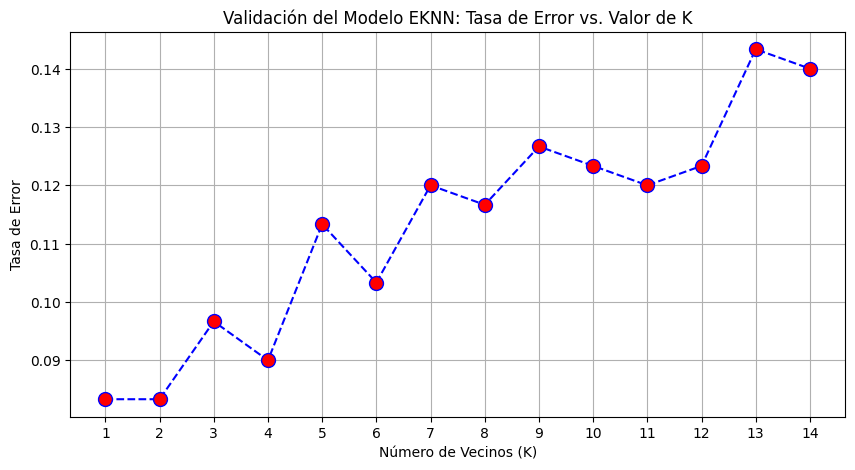

🏆 El valor óptimo es K = 1 (Menor error)

🤖 Entrenando Modelo Final EKNN con K=1...
🌟 EXACTITUD FINAL EKNN (Accuracy): 91.67%


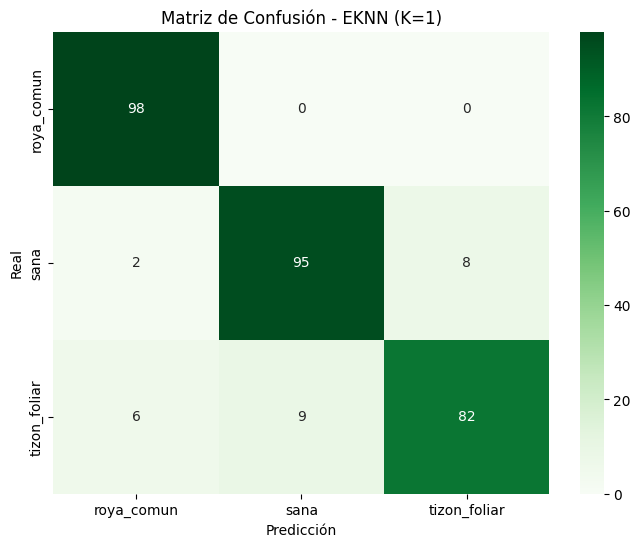


💾 Modelo guardado como: 'modelo_final_eknn.pkl'


In [11]:
# @title CELDA 6-D: Implementación EKNN con Validación Científica (DenseNet + KNN)
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, applications
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

# --- 1. CONFIGURACIÓN DEL EXTRACTOR DE CARACTERÍSTICAS (DenseNet121) ---
print("⚙️ Configurando 'Ojos' (Extractor DenseNet121)...")

# Base: DenseNet121 sin la parte de clasificación, solo para ver texturas
base_model = applications.DenseNet121(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3),
    pooling='avg'
)
base_model.trainable = False

# Pipeline de entrada: Igual que en el preprocesamiento
inputs = layers.Input(shape=(224, 224, 3))
# Revertimos la normalización (0-1 -> 0-255) porque DenseNet tiene su propio preprocesamiento
x = layers.Rescaling(255.0)(inputs)
x = applications.densenet.preprocess_input(x)
features = base_model(x, training=False)

# Modelo final de extracción
extractor_model = models.Model(inputs, features)
print("✅ Extractor configurado.")

# --- 2. FUNCIÓN PARA CONVERTIR IMÁGENES A VECTORES NUMÉRICOS ---
def extract_data(dataset, desc="datos"):
    print(f"🚀 Extrayendo características de {desc} (Esto toma tiempo)...")
    X, y = [], []
    # Recorremos el dataset por lotes
    for images, labels in dataset:
        feats = extractor_model.predict(images, verbose=0)
        X.append(feats)
        y.append(labels.numpy())
    return np.vstack(X), np.hstack(y)

# --- 3. EXTRACCIÓN REAL ---
# Usamos los datasets creados en la Celda 5
if 'train_dataset' not in globals():
    raise ValueError("❌ Error: No existe 'train_dataset'. Ejecuta la Celda 5 primero.")

X_train, y_train = extract_data(train_dataset, "ENTRENAMIENTO")
X_test, y_test = extract_data(val_dataset, "VALIDACIÓN") 

print(f"✅ Extracción terminada. Dimensiones: {X_train.shape}")

# --- 4. VALIDACIÓN DEL HIPERPARÁMETRO K (La Gráfica Científica) ---
print("\n📊 Calculando el mejor valor de K (Validación)...")
error_rate = []
k_range = range(1, 15) # Probamos de 1 a 14 vecinos

for i in k_range:
    # KNN temporal
    knn = KNeighborsClassifier(n_neighbors=i, weights='distance', metric='manhattan', n_jobs=-1)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    # Guardamos la tasa de error (promedio de fallos)
    error_rate.append(np.mean(pred_i != y_test))

# --- 5. GRAFICAR ERROR VS K ---
plt.figure(figsize=(10, 5))
plt.plot(k_range, error_rate, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Validación del Modelo EKNN: Tasa de Error vs. Valor de K')
plt.xlabel('Número de Vecinos (K)')
plt.ylabel('Tasa de Error')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Seleccionar el mejor K automáticamente
best_k = k_range[np.argmin(error_rate)]
print(f"🏆 El valor óptimo es K = {best_k} (Menor error)")

# --- 6. ENTRENAMIENTO FINAL ---
print(f"\n🤖 Entrenando Modelo Final EKNN con K={best_k}...")
final_knn = KNeighborsClassifier(n_neighbors=best_k, weights='distance', metric='manhattan', n_jobs=-1)
final_knn.fit(X_train, y_train)

# --- 7. EVALUACIÓN Y GUARDADO ---
y_pred_final = final_knn.predict(X_test)
acc_final = accuracy_score(y_test, y_pred_final)

print("="*50)
print(f"🌟 EXACTITUD FINAL EKNN (Accuracy): {acc_final:.2%}")
print("="*50)

# Matriz
cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Matriz de Confusión - EKNN (K={best_k})')
plt.ylabel('Real')
plt.xlabel('Predicción')
plt.show()

# Guardar el cerebro (KNN)
joblib.dump(final_knn, 'modelo_final_eknn.pkl')
print("\n💾 Modelo guardado como: 'modelo_final_eknn.pkl'")

🔍 Evaluando modelo EKNN con K=1...
   Total de muestras de prueba: 300
✅ Predicciones completadas.
------------------------------------------------------------

📊 REPORTE DE CLASIFICACIÓN (Métricas Oficiales):

              precision    recall  f1-score   support

  roya_comun     0.9245    1.0000    0.9608        98
        sana     0.9135    0.9048    0.9091       105
tizon_foliar     0.9111    0.8454    0.8770        97

    accuracy                         0.9167       300
   macro avg     0.9164    0.9167    0.9156       300
weighted avg     0.9163    0.9167    0.9156       300



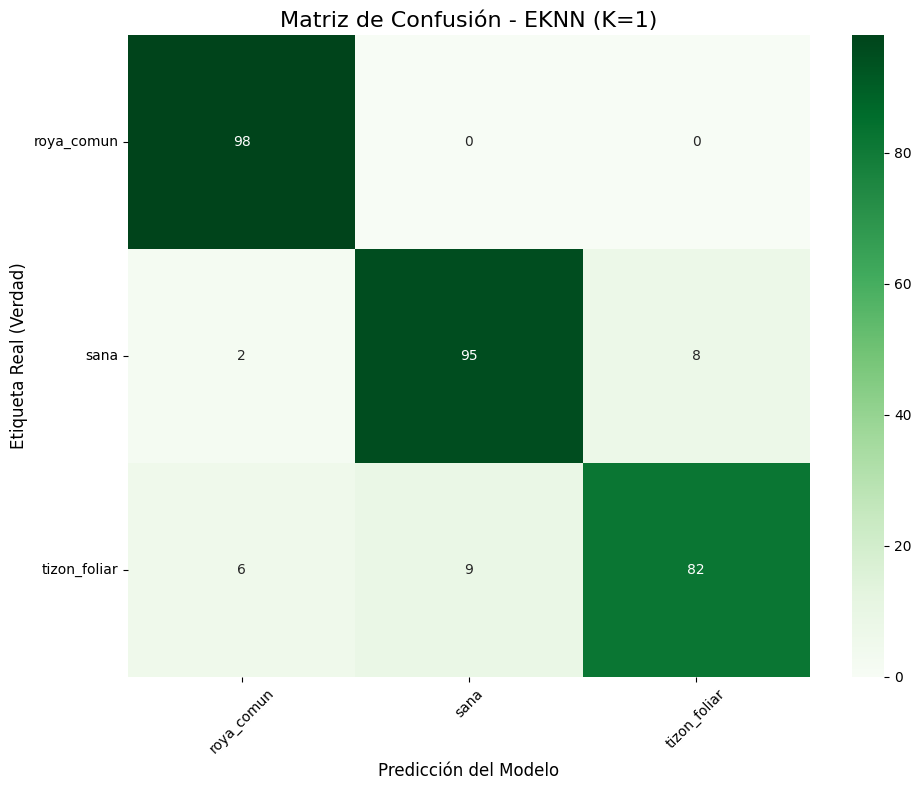

------------------------------------------------------------
🏆 EXACTITUD GLOBAL (Accuracy): 91.67%
------------------------------------------------------------


In [12]:
# @title CELDA 7: Evaluación Final de Métricas y Matriz (Adaptado a EKNN)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# --- 1. VERIFICACIÓN DE DATOS PREVIOS ---
# Aseguramos que existan los datos generados en la Celda 6-D
if 'final_knn' not in globals() or 'X_test' not in globals():
    print("❌ ERROR: No se encuentran las variables del EKNN.")
    print("   👉 Ejecuta primero la CELDA 6-D completa.")
    raise ValueError("Faltan datos del modelo EKNN")

print(f"🔍 Evaluando modelo EKNN con K={final_knn.n_neighbors}...")
print(f"   Total de muestras de prueba: {len(X_test)}")

# --- 2. GENERAR PREDICCIONES ---
# En EKNN no necesitamos iterar por batches, el modelo predice directo sobre los features
y_pred = final_knn.predict(X_test)
y_true = y_test  # Ya lo teníamos extraído de la celda anterior

print("✅ Predicciones completadas.")
print("-" * 60)

# --- 3. REPORTE DE CLASIFICACIÓN ---
print("\n📊 REPORTE DE CLASIFICACIÓN (Métricas Oficiales):\n")

report = classification_report(
    y_true, 
    y_pred, 
    target_names=class_names, # Nombres de las enfermedades
    digits=4 # 4 decimales para precisión científica
)
print(report)

# --- 4. MATRIZ DE CONFUSIÓN (GRÁFICO) ---
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True,         # Mostrar números
    fmt='d',            # Sin decimales
    cmap='Greens',      # Color verde (típico de agricultura/biología)
    xticklabels=class_names,
    yticklabels=class_names
)

# Título dinámico con el valor de K
plt.title(f'Matriz de Confusión - EKNN (K={final_knn.n_neighbors})', fontsize=16)
plt.ylabel('Etiqueta Real (Verdad)', fontsize=12)
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# --- 5. RESULTADO FINAL ---
acc = np.sum(y_pred == y_true) / len(y_true)
print("-" * 60)
print(f"🏆 EXACTITUD GLOBAL (Accuracy): {acc:.2%}")
print("-" * 60)

⚙️ Iniciando sistema...
✅ Modelo EKNN cargado correctamente.
✅ Extractor DenseNet121 listo.

📂 Selecciona una imagen para diagnóstico...


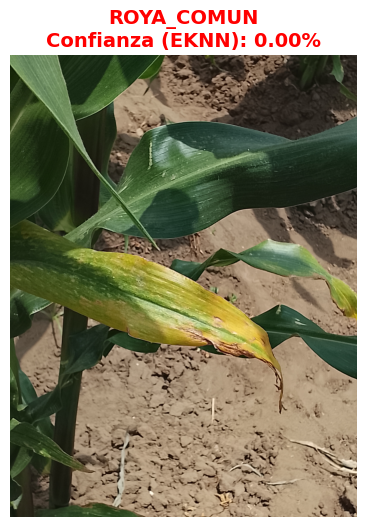


🌽 RESULTADO DEL DIAGNÓSTICO
➡️ Clase predicha      : ROYA_COMUN
📊 Confianza (EKNN)    : 0.00%
📐 Distancia promedio : 20.516794
⏱️ Tiempo inferencia  : 3.4745 segundos


In [17]:
# ============================================================
# CELDA 13: PREDICCIÓN RÁPIDA CON EKNN (VERSIÓN FINAL CORRECTA)
# ============================================================

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
import tkinter as tk
from tkinter import filedialog
from tensorflow.keras import applications, layers, models
from tensorflow.keras.preprocessing import image

# ------------------------------------------------------------
# 1. CARGA DEL MODELO EKNN (CEREBRO)
# ------------------------------------------------------------
print("⚙️ Iniciando sistema...")

try:
    knn_model = joblib.load("modelo_final_eknn.pkl")
    print("✅ Modelo EKNN cargado correctamente.")
except Exception as e:
    print("❌ Error al cargar 'modelo_final_eknn.pkl'")
    raise e

# ------------------------------------------------------------
# 2. MODELO DE EXTRACCIÓN DE CARACTERÍSTICAS (OJOS)
# ------------------------------------------------------------
base_model = applications.DenseNet121(
    include_top=False,
    weights="imagenet",
    pooling="avg"
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = applications.densenet.preprocess_input(inputs)  # ✅ normalización correcta
features = base_model(x, training=False)

vision_model = models.Model(inputs, features)
print("✅ Extractor DenseNet121 listo.")

# ------------------------------------------------------------
# 3. SELECCIÓN DE IMAGEN
# ------------------------------------------------------------
print("\n📂 Selecciona una imagen para diagnóstico...")
root = tk.Tk()
root.attributes("-topmost", True)
root.withdraw()

file_path = filedialog.askopenfilename(
    filetypes=[("Imágenes", "*.jpg *.png *.jpeg")]
)
root.destroy()

if not file_path:
    print("❌ No se seleccionó ninguna imagen.")
    raise SystemExit

# ------------------------------------------------------------
# 4. PREPROCESAMIENTO DE IMAGEN (SIN NORMALIZACIONES FALSAS)
# ------------------------------------------------------------
img = image.load_img(file_path, target_size=(224, 224))
img_array = image.img_to_array(img)          # ✅ SIN /255
img_batch = np.expand_dims(img_array, axis=0)

# ------------------------------------------------------------
# 5. PREDICCIÓN EKNN (CLASE)
# ------------------------------------------------------------
start = time.time()

features_vector = vision_model.predict(img_batch, verbose=0)

pred_idx = knn_model.predict(features_vector)[0]

end = time.time()

# ------------------------------------------------------------
# 6. CONFIANZA REAL BASADA EN DISTANCIA EKNN
# ------------------------------------------------------------
# Distancias reales a los k vecinos
distances, _ = knn_model.kneighbors(features_vector)

# Distancia promedio
mean_distance = np.mean(distances)

# Confianza basada exclusivamente en el modelo:
# menor distancia => mayor similitud
confidence = np.exp(-mean_distance) * 100
confidence = np.clip(confidence, 0, 100)

# Clases (mismo orden que el entrenamiento)
class_names = ['roya_comun', 'sana', 'tizon_foliar']
label = class_names[pred_idx]

# ------------------------------------------------------------
# 7. VISUALIZACIÓN
# ------------------------------------------------------------
plt.figure(figsize=(6, 6))
plt.imshow(image.load_img(file_path))
plt.axis("off")

if confidence >= 85:
    color = "green"
elif confidence >= 65:
    color = "orange"
else:
    color = "red"

plt.title(
    f"{label.upper()}\nConfianza (EKNN): {confidence:.2f}%",
    fontsize=14,
    fontweight="bold",
    color=color
)

plt.show()

# ------------------------------------------------------------
# 8. SALIDA EN CONSOLA
# ------------------------------------------------------------
print("\n🌽 RESULTADO DEL DIAGNÓSTICO")
print(f"➡️ Clase predicha      : {label.upper()}")
print(f"📊 Confianza (EKNN)    : {confidence:.2f}%")
print(f"📐 Distancia promedio : {mean_distance:.6f}")
print(f"⏱️ Tiempo inferencia  : {end - start:.4f} segundos")



📂 Imagen cargada:
D:/DECIMO CICLO USS/INVESTIGACION II/maiz_dataset/roya_comun/IMG_20251005_115104.jpg



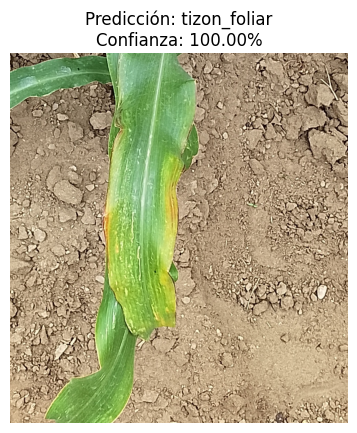

🔎 Resultado Final:
  📌 Enfermedad Detectada: tizon_foliar
  🔥 Confianza del Modelo: 100.00%


In [10]:
# ======== CLASIFICACIÓN INDIVIDUAL CON EKNN + DENSENET ========

import numpy as np
import tensorflow as tf
import joblib
from tensorflow.keras.preprocessing import image
import tkinter as tk
from tkinter import filedialog
import matplotlib.pyplot as plt

# ========= CARGAR MODELO ========
final_knn = joblib.load("modelo_final_eknn.pkl")  # <--- tu modelo entrenado

# ======== CARGAR EXTRACTOR DENSENET ========
base_model = tf.keras.applications.DenseNet121(
    include_top=False, weights='imagenet', pooling='avg'
)
base_model.trainable = False

inputs = tf.keras.layers.Input(shape=(224, 224, 3))
x = tf.keras.layers.Rescaling(255.0)(inputs)
x = tf.keras.applications.densenet.preprocess_input(x)
features = base_model(x, training=False)
extractor_model = tf.keras.Model(inputs, features)

# ======== CLASES (MISMAS DEL ENTRENAMIENTO) ========
class_names = ["mancha_gris_foliar","roya_comun","sana","tizon_foliar"]

# ======== SELECCIONAR IMAGEN DESDE EXPLORADOR WINDOWS ========
root = tk.Tk()
root.withdraw()
file_path = filedialog.askopenfilename(filetypes=[("Imágenes","*.jpg;*.jpeg;*.png")])

if not file_path:
    print("❌ No seleccionaste ninguna imagen.")
    exit()

print(f"\n📂 Imagen cargada:\n{file_path}\n")

# ======== PREPROCESAR IMAGEN ========
img = tf.keras.preprocessing.image.load_img(file_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)

# ======== EXTRAER FEATURES ========
vec = extractor_model.predict(img_arr, verbose=0)

# ======== PREDICCIÓN ========
pred = final_knn.predict(vec)[0]
prob = np.max(final_knn.predict_proba(vec)) * 100

pred_name = class_names[pred]

# ======== MOSTRAR RESULTADO ========
plt.imshow(image.load_img(file_path))
plt.axis("off")
plt.title(f"Predicción: {pred_name}\nConfianza: {prob:.2f}%")
plt.show()

print(f"🔎 Resultado Final:")
print(f"  📌 Enfermedad Detectada: {pred_name}")
print(f"  🔥 Confianza del Modelo: {prob:.2f}%")
